# Metric MDS of n equidistant points: the regular polygon is optimal only for small n

Makes the figure `reg-poly`. All pairwise distances are 1. (a) Metric MDS (SMACOF from random initializations)
of n = 2, 3, 4, 8, 12, 14, 16 equidistant points. (b) The average stress (mean squared error over all pairs) of
the metric MDS solution (mean ± std over three seeds) and of the optimally scaled regular polygon, against n. The
dotted lines are the limits for large n: 1 - pi^2/12 for the MDS solution and 1 - 8/pi^2 for the polygon.

Self-contained: the MDS fits are computed here (about a minute on one core), nothing is read from `results/`.

In [1]:
import sys
sys.path.insert(0, "..")  # make the modules in code/ importable

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

import paths

paths.FIGURES.mkdir(exist_ok=True)
if paths.STYLE.exists():
    plt.style.use(paths.STYLE)
else:
    print(f"{paths.STYLE} not found: using matplotlib's default style. Copy your mpl_style.txt there.")

In [2]:
def equidistant(n):
    D = np.ones((n, n))
    np.fill_diagonal(D, 0)
    return D


def average_stress(D, Z):
    """Mean squared difference between D and the distances of Z, over all pairs i != j."""
    n = len(D)
    return ((D - pairwise_distances(Z)) ** 2).sum() / (n * (n - 1))


def regular_polygon(n):
    """Regular n-gon with the radius that minimizes the stress for equidistant points."""
    theta = np.arange(n) / n * 2 * np.pi
    radius = 1 / (n * np.tan(np.pi / (2 * n)))
    return radius * np.stack([np.sin(theta), np.cos(theta)], axis=-1)


def rotate_to_top(Z):
    """Rotate so that point 0 sits on the positive y-axis."""
    angle = np.pi / 2 - np.arctan2(Z[0, 1], Z[0, 0])
    c, s = np.cos(angle), np.sin(angle)
    return Z @ np.array([[c, -s], [s, c]]).T

In [ ]:
SEEDS = [0, 1, 2]
PANEL_SEED = 1  # whose embeddings are drawn in panel a
ns = np.concatenate([np.arange(2, 20), [50, 100, 200, 500, 1000]])
ns_panels = [2, 3, 4, 8, 12, 14, 16]

# n_init=4 and init="random" were the defaults of scikit-learn < 1.9, with which the figure was first made
stress_mds = np.zeros((len(SEEDS), len(ns)))
embeddings = {}
for i, seed in enumerate(SEEDS):
    for j, n in enumerate(ns):
        D = equidistant(n)
        mds = MDS(metric="precomputed", metric_mds=True, n_init=4, init="random", normalized_stress=False, random_state=seed)
        Z = mds.fit_transform(D)
        stress_mds[i, j] = average_stress(D, Z)
        if seed == PANEL_SEED:
            embeddings[n] = Z
stress_polygon = np.array([average_stress(equidistant(n), regular_polygon(n)) for n in ns])
stress_mean, stress_std = stress_mds.mean(axis=0), stress_mds.std(axis=0)

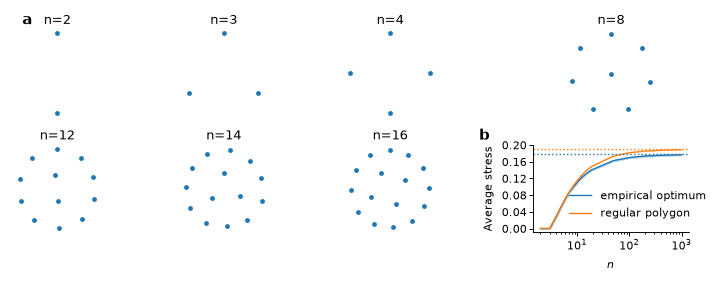

In [8]:
fig, axs = plt.subplots(2, 4, figsize=(5.5, 2), layout="constrained")
axs = axs.flatten()

for ax, n in zip(axs, ns_panels):
    Z = rotate_to_top(embeddings[n])
    r = np.linalg.norm(Z, axis=1).max() * 1.1  # margin around the points
    ax.scatter(Z[:, 0], Z[:, 1], s=10)
    ax.set_xlim(-r, r)
    ax.set_ylim(-r, r)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(f"n={n}")

ax = axs[-1]
(line_mds,) = ax.plot(ns, stress_mean, label="empirical optimum")
ax.fill_between(ns, stress_mean - stress_std, stress_mean + stress_std, alpha=0.3, color=line_mds.get_color())
(line_polygon,) = ax.plot(ns, stress_polygon, label="regular polygon")
ax.axhline(1 - np.pi**2 / 12, linestyle=":", color=line_mds.get_color())
ax.axhline(1 - 8 / np.pi**2, linestyle=":", color=line_polygon.get_color())
ax.legend(loc=(0.2, 0.1))
ax.set_xscale("log")
ax.set_xlabel("$n$")
ax.set_ylabel("Average stress")
ax.set_yticks(np.arange(0, 0.24, 0.04))

axs[0].text(0.1, 1.02, "a", transform=axs[0].transAxes, ha="left", va="bottom", fontweight="bold", fontsize=8)
axs[-1].text(-0.35, 1.02, "b", transform=axs[-1].transAxes, ha="left", va="bottom", fontweight="bold", fontsize=8)

for ext in ("png", "pdf"):
    fig.savefig(paths.FIGURES / f"reg-poly.{ext}", dpi=300)